Produces Fig. 1(a) and Fig. 1(b) of the paper.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ---------------------------------------------------------
# 1. Experiment Settings
# ---------------------------------------------------------
n_values = [100, 200, 400, 800, 1600, 2500]
alpha = 1.0
tau = 2.0
eta_a = 0.8
eta_f = 0.8
lambda_ = 0.01
ghost_batch_size = 500

results = {"n": [], "raw": [], "spike": [], "dev_tilde": [], "remainder": []}


def run_scaling_sim(n):
    k = int(alpha * n)
    steps = int(tau * n)
    lr_a = eta_a / k
    lr_f = eta_f / k

    rng = np.random.default_rng(42)
    xi = rng.normal(0, 1, n)
    xi /= np.linalg.norm(xi)
    F = rng.normal(0, 1 / np.sqrt(n), (k, n))
    a = rng.normal(0, 1, k)

    C_raw = np.eye(k) / n
    C_tilde = np.eye(k) / n
    C_spike = np.zeros((k, k))

    def teacher_func(z):
        return np.tanh(z)

    def sigma(x):
        return np.maximum(x, 0)

    def sigma_prime(x):
        return (x > 0).astype(float)

    for t in range(steps):
        # Forward
        z0 = rng.normal()
        g_train = rng.normal(0, 1, n)
        g_train -= np.dot(g_train, xi) * xi
        x_train = z0 * xi + g_train
        h = F @ x_train
        e = (np.dot(a, sigma(h)) / k) - teacher_func(z0)
        v_t = e * a * sigma_prime(h)

        # Ghost Batch for mu_t
        g_ghost = rng.normal(0, 1, (ghost_batch_size, n))
        g_ghost -= np.outer(g_ghost @ xi, xi)
        x_ghost = np.outer(np.ones(ghost_batch_size), z0 * xi) + g_ghost
        h_ghost = x_ghost @ F.T
        e_ghost = ((sigma(h_ghost) @ a) / k) - teacher_func(z0)
        mu_t = np.mean(e_ghost[:, None] * a[None, :] * sigma_prime(h_ghost), axis=0)

        # Components
        v_tilde_t = v_t - mu_t

        # Accumulate
        scale = (eta_f / k) ** 2
        C_raw += scale * np.outer(v_t, v_t)
        C_tilde += scale * np.outer(v_tilde_t, v_tilde_t)
        C_spike += scale * np.outer(mu_t, mu_t)

        # Update
        a -= lr_a * (e * sigma(h) + lambda_ * a)
        F -= lr_f * np.outer(v_t, x_train)

    # --- Final Measurements ---
    # 0. Raw Magnitude
    norm_raw = np.linalg.norm(C_raw, "fro")

    # 1. Spike Magnitude
    norm_spike = np.linalg.norm(C_spike, "fro")

    # 2. Centered Deviation
    c_tilde = np.trace(C_tilde) / k
    dev_tilde = np.linalg.norm(C_tilde - c_tilde * np.eye(k), "fro")

    # 3. Remainder Magnitude
    R_matrix = C_raw - C_tilde - C_spike
    norm_rem = np.linalg.norm(R_matrix, "fro")

    return norm_raw, norm_spike, dev_tilde, norm_rem


# ---------------------------------------------------------
# 2. Execute Sweep
# ---------------------------------------------------------
print(f"Running scaling sweep for n = {n_values}...")

for n in tqdm(n_values):
    r, s, d, rem = run_scaling_sim(n)
    results["n"].append(n)
    results["raw"].append(r)
    results["spike"].append(s)
    results["dev_tilde"].append(d)
    results["remainder"].append(rem)

ns = np.array(results["n"])
raws = np.array(results["raw"])
spikes = np.array(results["spike"])
tildes = np.array(results["dev_tilde"])
rems = np.array(results["remainder"])

# Print values
print("ns:", ns)
print("Raw values:", raws)
print("Spike values:", spikes)
print("Centered Deviation values:", tildes)
print("Remainder values:", rems)

# Slopes
slope_raw = np.polyfit(np.log(ns), np.log(raws), 1)[0]
slope_spike = np.polyfit(np.log(ns), np.log(spikes), 1)[0]
slope_tilde = np.polyfit(np.log(ns), np.log(tildes), 1)[0]
slope_rem = np.polyfit(np.log(ns), np.log(rems), 1)[0]
print(f"Slope Raw:       {slope_raw:.3f}") 
print(f"Slope Spike:     {slope_spike:.3f}")
print(f"Slope Centered:  {slope_tilde:.3f}")
print(f"Slope Remainder: {slope_rem:.3f}")

Running scaling sweep for n = [100, 200, 400, 800, 1600, 2500]...
ns: [ 100  200  400  800 1600 2500]
Raw values: [0.1507115  0.12221521 0.11044358 0.10399051 0.10100419 0.09795061]
Spike values: [0.08202397 0.0817186  0.08990002 0.09027086 0.09215501 0.09158342]
Centered Deviation values: [0.0157854  0.01098787 0.00883724 0.00721938 0.00626808 0.0058038 ]
Remainder values: [0.01111257 0.0077597  0.00600008 0.00403972 0.00288309 0.00242317]
Slope Raw:       -0.122
Slope Spike:     0.040
Slope Centered:  -0.301
Slope Remainder: -0.477


100%|██████████| 6/6 [22:53<00:00, 228.85s/it]


In [2]:
import matplotlib as mpl
import scienceplots

mpl.rcParams.update(mpl.rcParamsDefault)

plt.style.use(["science", "bright"])
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times"],
        "font.size": 15.3,
        "axes.labelsize": 17.4,
        "figure.dpi": "600",
        # turn off LaTeX
        "text.usetex": False,
    }
)

colors = ["#0072B2", "#D55E00", "#CC79A7", "#F0E442"]

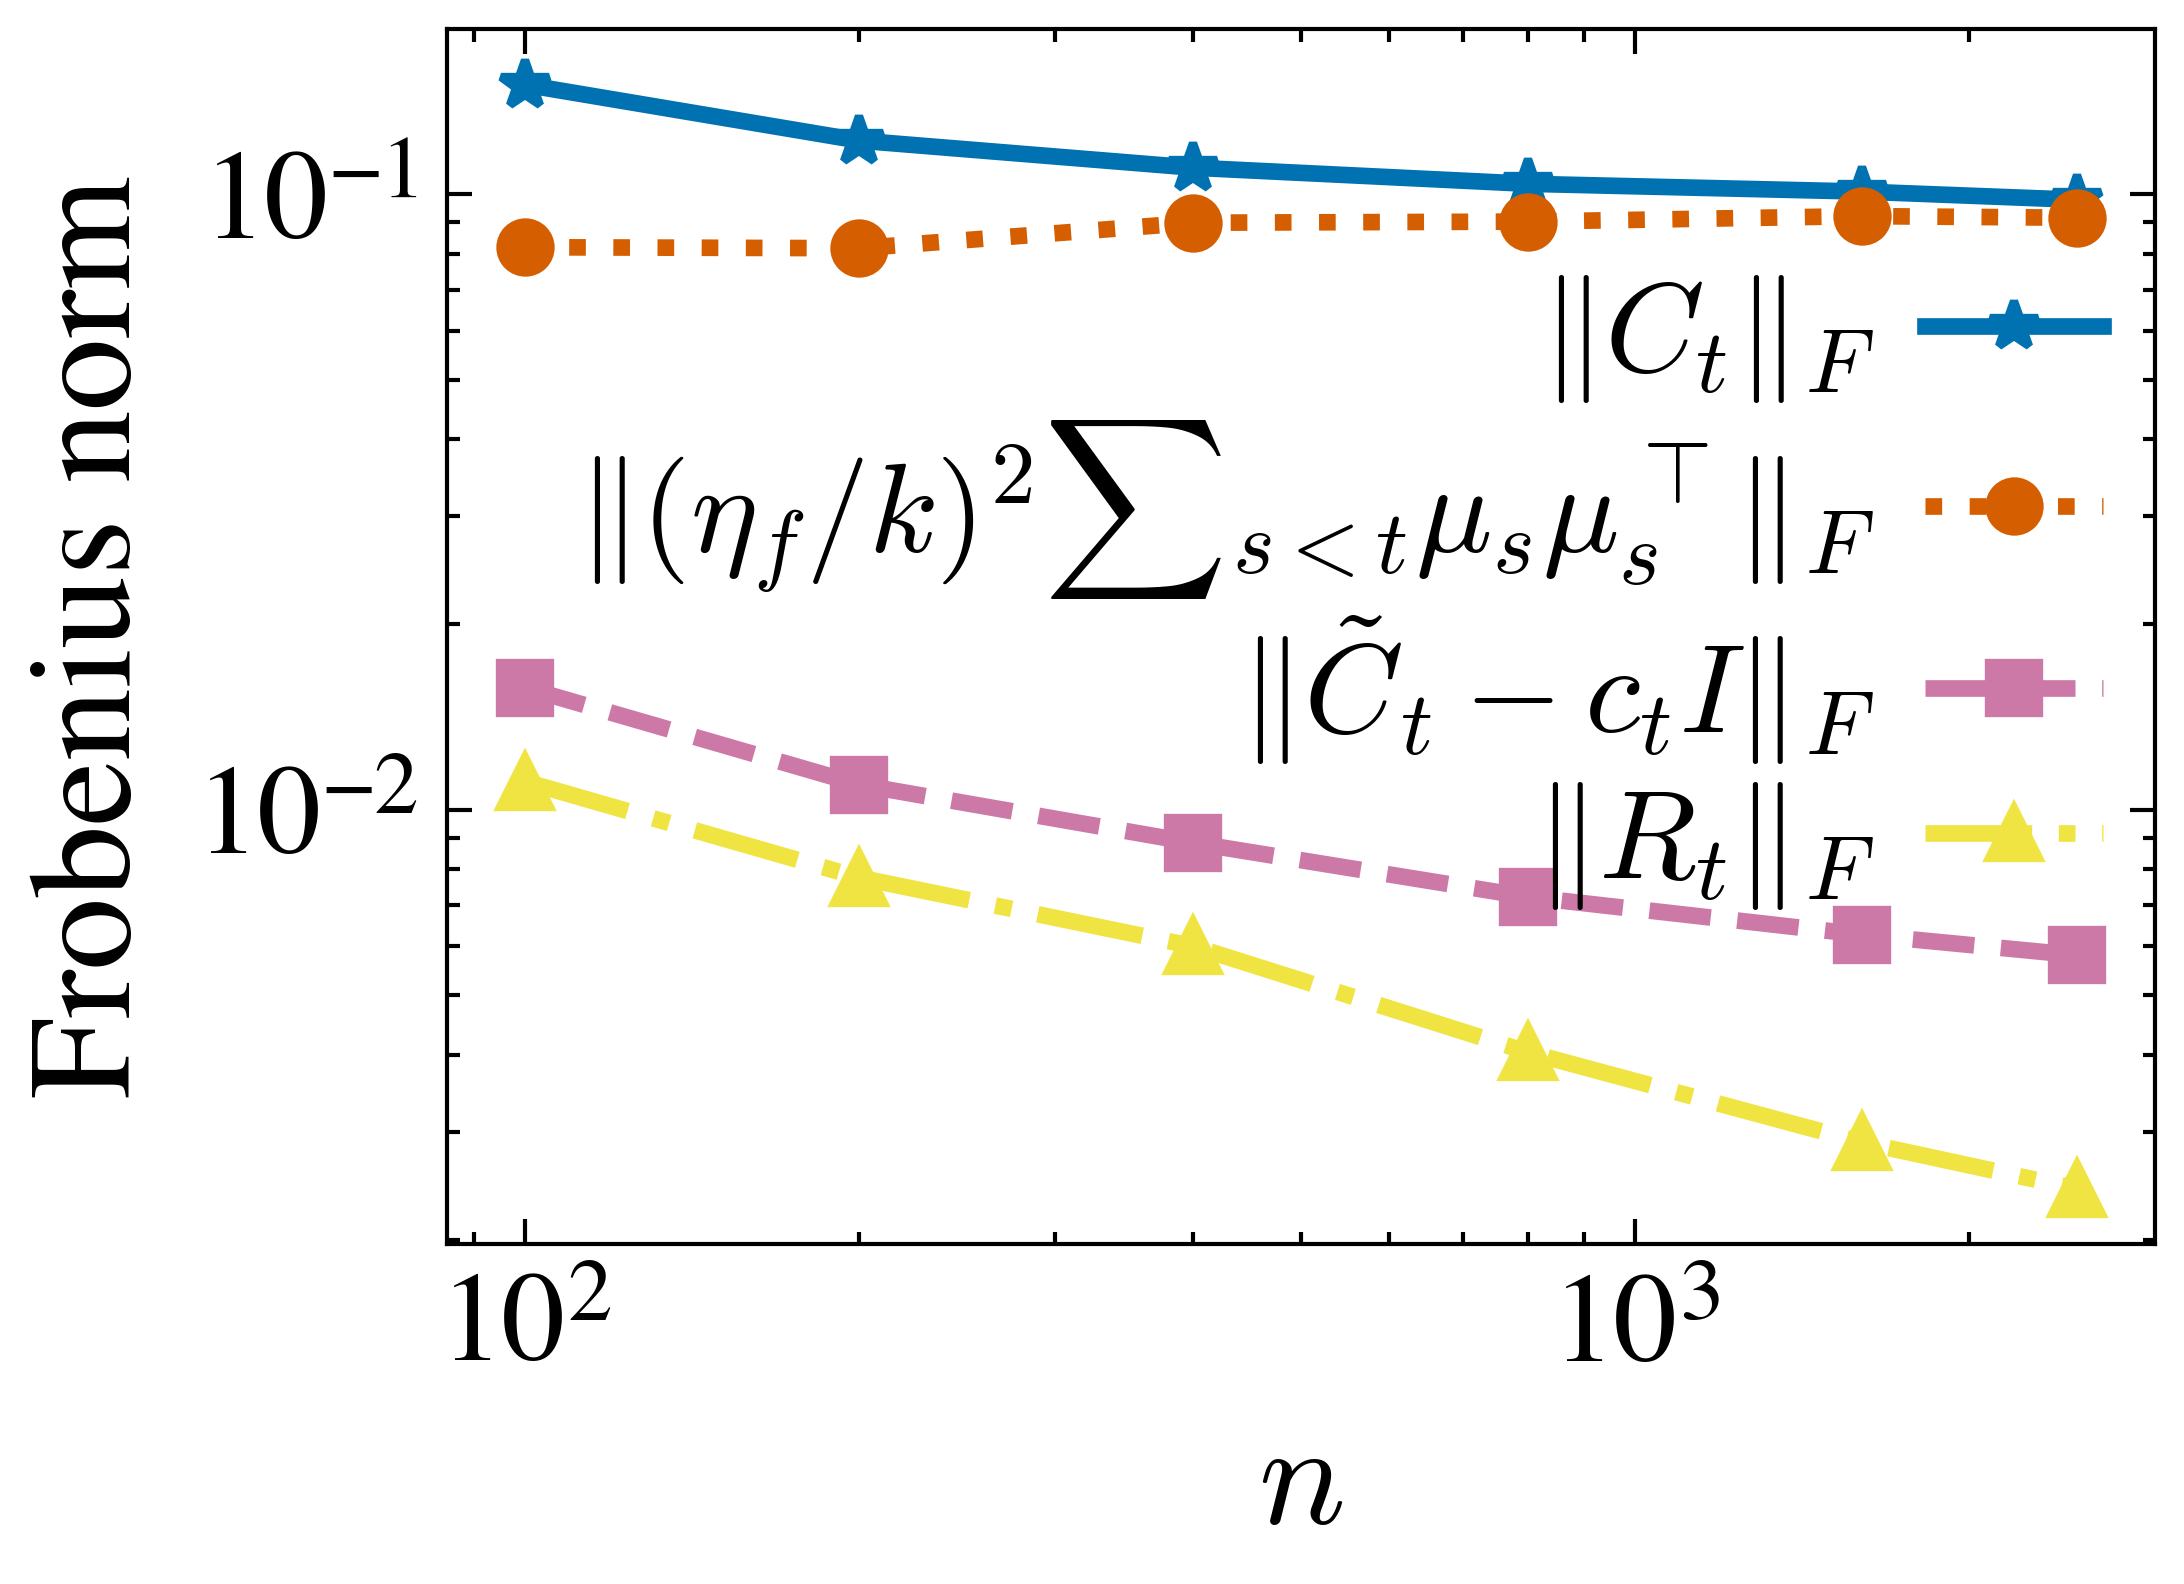

In [3]:
# Plot Data
plt.figure(figsize=(4, 3))
plt.plot(
    ns,
    raws,
    color=colors[0],
    marker="*",
    linestyle="solid",
    label=r"$\|C_t\|_F$",
    linewidth=2,
)
plt.plot(
    ns,
    spikes,
    color=colors[1],
    marker="o",
    linestyle="dotted",
    label=r"$\|(\eta_f/k)^2 {\sum}_{s<t} \mu_s\mu_s^\top\|_F$",
    linewidth=2,
)
plt.plot(
    ns,
    tildes,
    color=colors[2],
    marker="s",
    linestyle="dashed",
    label=r"$\|\tilde{C}_t - c_t I \|_F$",
    linewidth=2,
)
plt.plot(
    ns,
    rems,
    color=colors[3],
    marker="^",
    linestyle="dashdot",
    label=r"$\|R_t\|_F$",
    linewidth=2,
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$n$")
plt.ylabel(r"Frobenius norm")
plt.legend(loc="upper right", bbox_to_anchor=(0.97, 0.8), handlelength=1.4, handletextpad=0.4, labelspacing=0.1, borderaxespad=0.0, borderpad=0.0, markerfirst=False, alignment="right")
plt.tight_layout()
plt.show()

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ---------------------------------------------------------
# 1. Experiment Settings
# ---------------------------------------------------------
alpha = 1.0
tau = 2.0
eta_a = 0.8
eta_f = 0.8
lambda_ = 0.01
ghost_batch_size = 500

results = {"n": [], "raw": [], "spike": [], "dev_tilde": [], "remainder": []}


def run_scaling_sim(n):
    k = int(alpha * n)
    steps = int(tau * n)
    lr_a = eta_a / k
    lr_f = eta_f / k

    rng = np.random.default_rng(42)
    xi = rng.normal(0, 1, n)
    xi /= np.linalg.norm(xi)
    F = rng.normal(0, 1 / np.sqrt(n), (k, n))
    a = rng.normal(0, 1, k)

    C_raw = np.eye(k) / n
    C_tilde = np.eye(k) / n
    C_spike = np.zeros((k, k))

    def teacher_func(z):
        return np.tanh(z)

    def sigma(x):
        return np.maximum(x, 0)

    def sigma_prime(x):
        return (x > 0).astype(float)

    for t in tqdm(range(steps)):
        # Forward
        z0 = rng.normal()
        g_train = rng.normal(0, 1, n)
        g_train -= np.dot(g_train, xi) * xi
        x_train = z0 * xi + g_train
        h = F @ x_train
        e = (np.dot(a, sigma(h)) / k) - teacher_func(z0)
        v_t = e * a * sigma_prime(h)

        # Ghost Batch for mu_t
        g_ghost = rng.normal(0, 1, (ghost_batch_size, n))
        g_ghost -= np.outer(g_ghost @ xi, xi)
        x_ghost = np.outer(np.ones(ghost_batch_size), z0 * xi) + g_ghost
        h_ghost = x_ghost @ F.T
        e_ghost = ((sigma(h_ghost) @ a) / k) - teacher_func(z0)
        mu_t = np.mean(e_ghost[:, None] * a[None, :] * sigma_prime(h_ghost), axis=0)

        # Components
        v_tilde_t = v_t - mu_t

        # Accumulate
        scale = (eta_f / k) ** 2
        C_raw += scale * np.outer(v_t, v_t)
        C_tilde += scale * np.outer(v_tilde_t, v_tilde_t)
        C_spike += scale * np.outer(mu_t, mu_t)

        # Update
        a -= lr_a * (e * sigma(h) + lambda_ * a)
        F -= lr_f * np.outer(v_t, x_train)

    R_matrix = C_raw - C_tilde - C_spike

    return C_raw, C_spike, C_tilde, R_matrix

n = 1000
C_raw, C_spike, C_tilde, R_matrix = run_scaling_sim(n)

100%|██████████| 2000/2000 [01:58<00:00, 16.87it/s]


In [5]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import scienceplots
import numpy as np

mpl.rcParams.update(mpl.rcParamsDefault)

plt.style.use(["science", "bright"])
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times"],
        "font.size": 14.9,
        "axes.labelsize": 17.0,
        "figure.dpi": "600",
    }
)

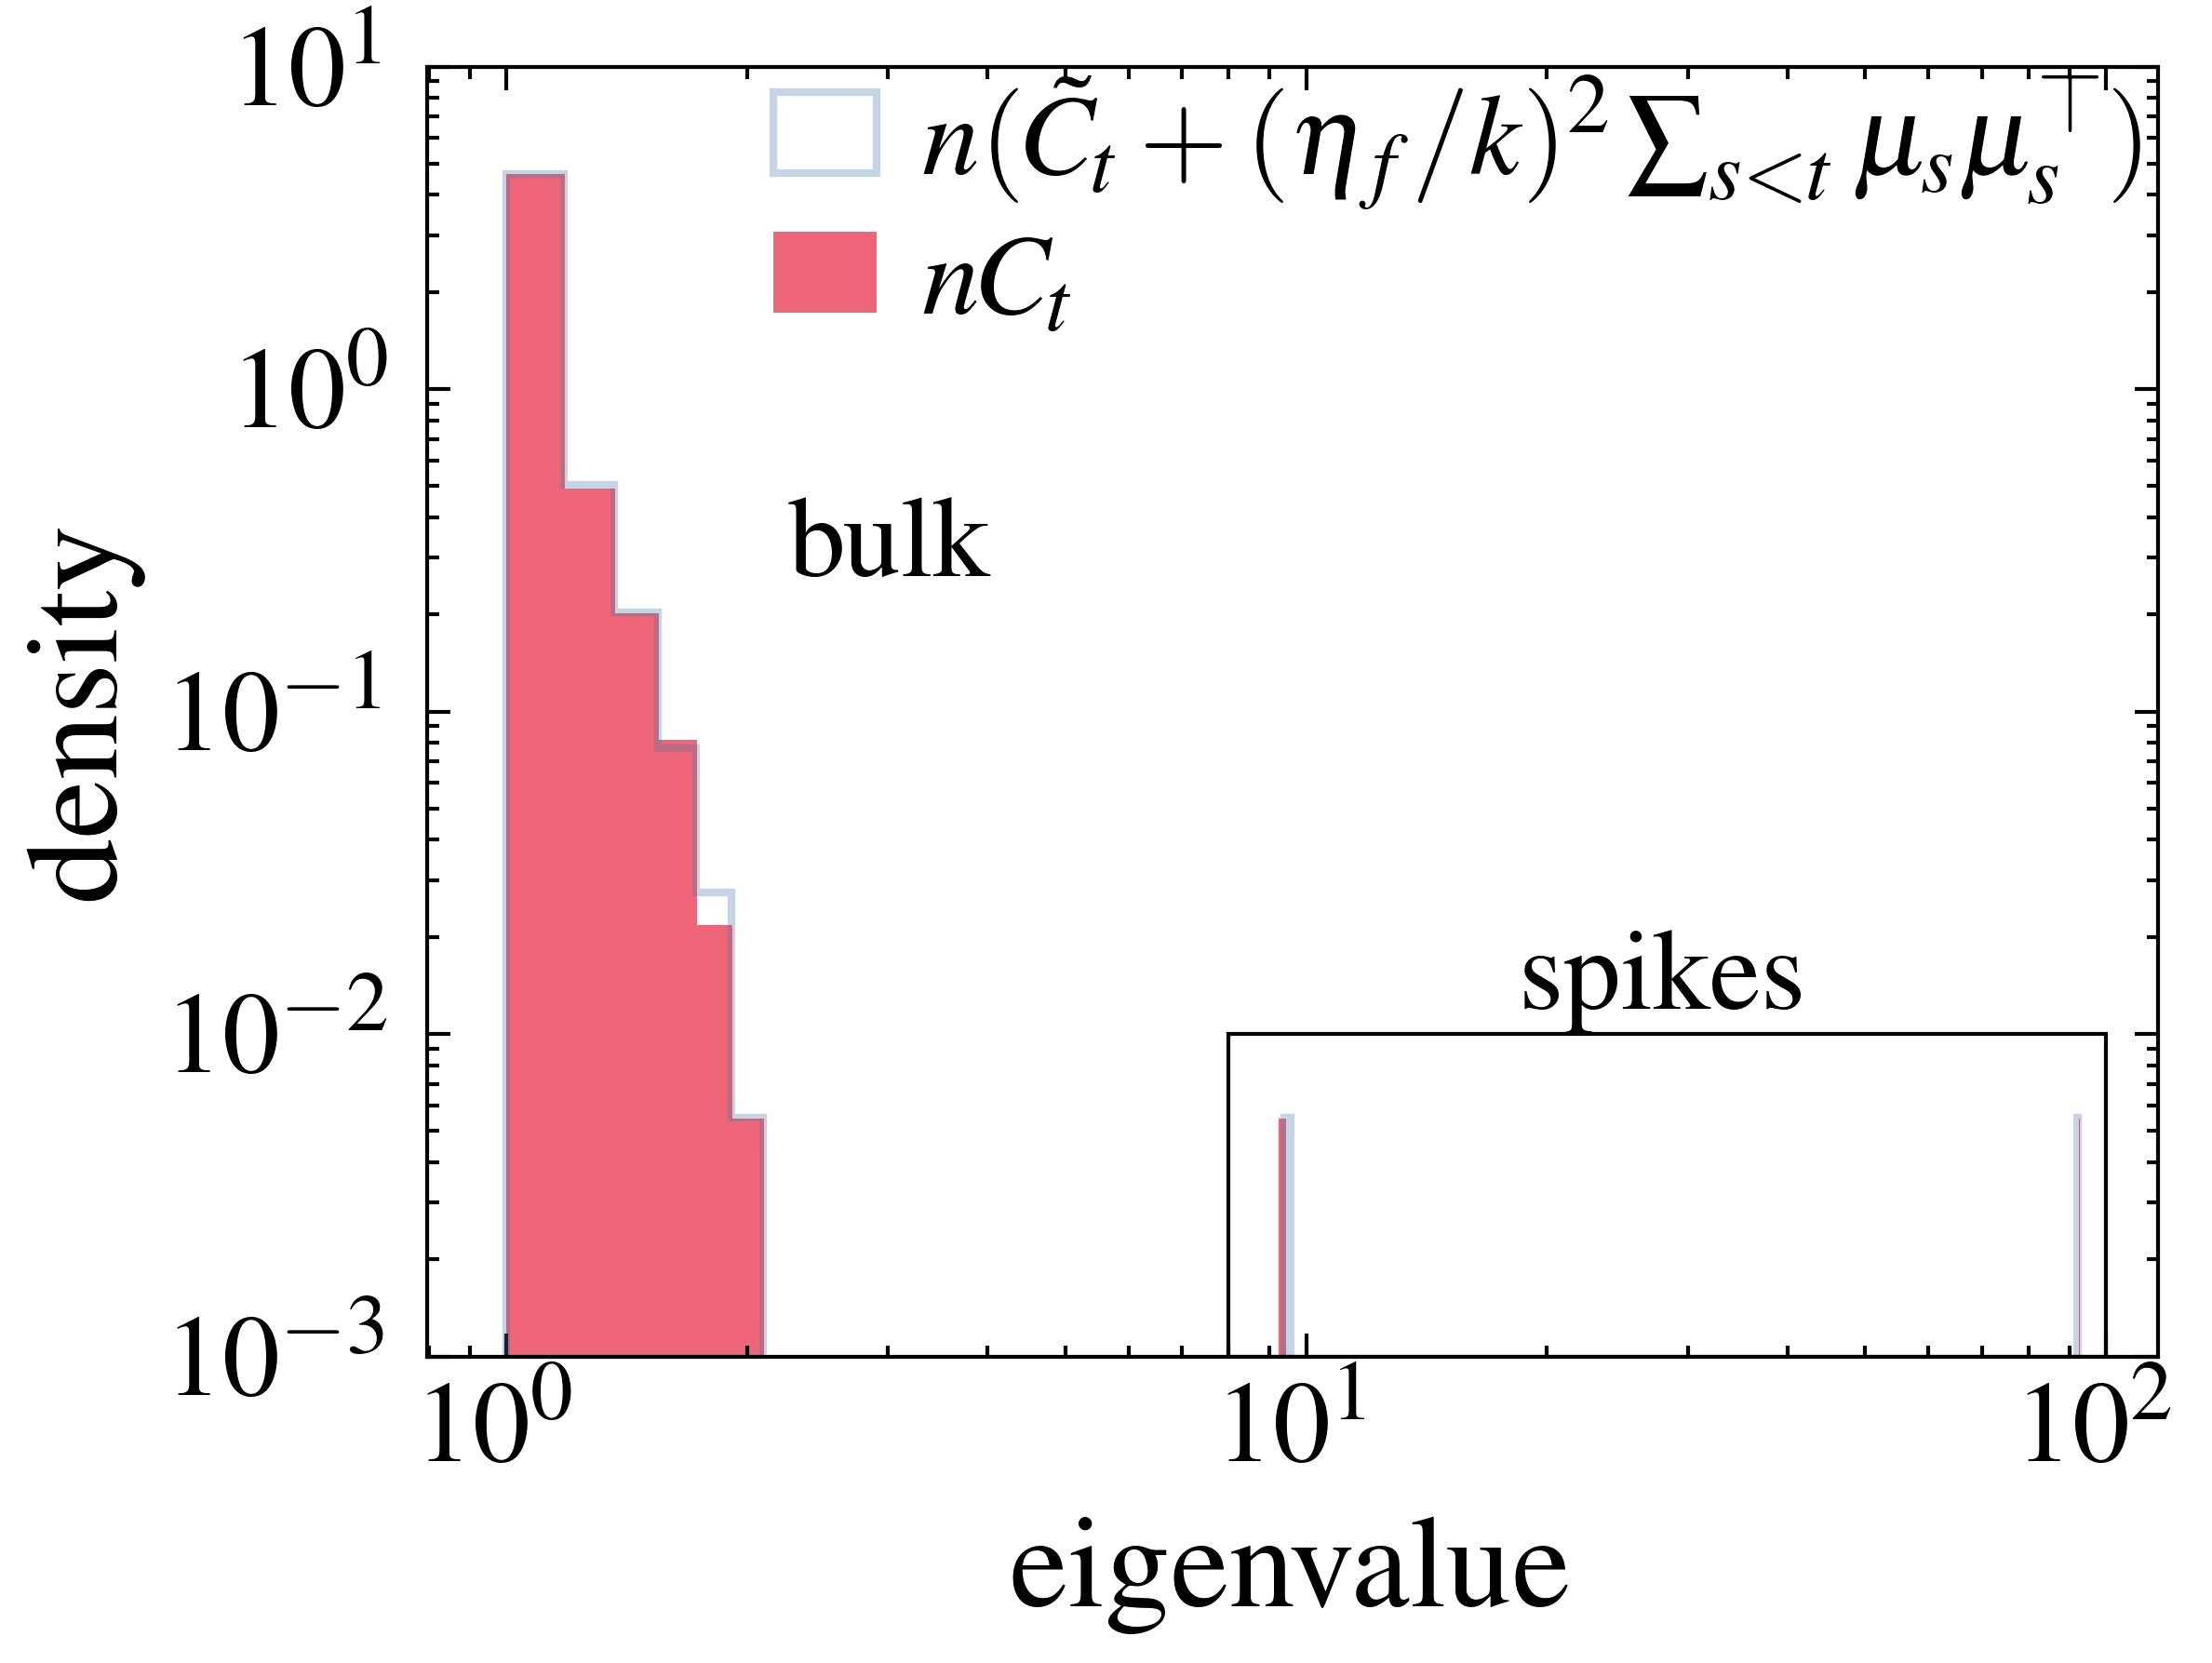

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Calculate eigenvalues of C_raw
C_raw_eig = np.linalg.eigvals(C_raw * n)
C_approx_eig = np.linalg.eigvals((C_spike + C_tilde) * n)

# plot eigenvalue histogram
fig, ax = plt.subplots(figsize=(4, 3))

ax.hist(
    C_approx_eig,
    bins=500,
    density=True,
    alpha=0.3,
    histtype="step",
    label=r"$n (\Tilde{C}_t +(\eta_f/k)^2 \sum_{s<t} \mu_s\mu_s^\top)$",
)
ax.hist(C_raw_eig, bins=500, density=True, label=r"$n C_t$")

ax.legend(loc="upper right", handlelength=0.9, handletextpad=0.4, labelspacing=0.2, borderpad=0.05, borderaxespad=0.0)
ax.set_xlabel("eigenvalue")
ax.set_ylabel("density")
ax.set_ylim(0.001, 1e1)
ax.set_yscale("log")
ax.set_xscale("log")

# --- Box around spikes region ---
x0, x1 = 8, 100
y0, y1 = 1e-3, 1e-2
rect = Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, linewidth=0.5)
ax.add_patch(rect)

# Label the box
ax.text((x0 * x1) ** 0.5, y1, "spikes", va="bottom", ha="center")

ax.text(2.25, 0.22, "bulk", va="bottom", ha="left")

plt.show()